# 6. Sentiment, and the quotation it has to produce

*Part of the [broadlisten](https://github.com/InteractionDataLab/broad-listening/tree/main/code)
stage-by-stage examples. Every number and figure below was produced by running
this notebook on the synthetic corpus in `broadlisten.sample`, which is
generated from templates and contains no participant data.*

Not a lexicon. A word list cannot see "it broke me and rebuilt me", which is the
register people actually write in, and it is English-only, so it marks every
other language as missing.

An instruction model reads the sentence instead. But a model that is
confabulating will happily return a confident label, so **every verdict must
quote the span of the response that carries the affect**. If that span is not in
the text, the verdict is refused.

In [1]:
from broadlisten.sentiment import SENTIMENT_SCALE, SENTIMENT_SHRINK

print(f"{'category':20s} {'value':>6} {'floor':>6}")
for k in SENTIMENT_SCALE:
    print(f"{k:20s} {SENTIMENT_SCALE[k]:6.2f} {SENTIMENT_SHRINK[k]:6.2f}")

category              value  floor
strongly_negative     -1.00  -0.60
negative              -0.60  -0.20
mixed                  0.00   0.00
neutral                0.00   0.00
positive               0.60   0.20
strongly_positive      1.00   0.60


Six **ordered** categories, and the number is derived here, in code, on
a fixed mapping. Asked for a float directly, an instruction model hedges toward
the middle and the scale loses its ends. Confidence shrinks a score toward its
category's floor and can never flip the sign the model committed to.

## The citation check, demonstrated

Two identical verdicts. The only difference is whether the quoted span is really
in the response.

In [2]:
from broadlisten.sentiment import score_responses
from broadlisten.sample import sample_corpus

# A response from the synthetic corpus, so the demonstration runs on the same
# material as every other notebook here.
TEXT = sample_corpus(seed=0).text.dropna().astype(str).iloc[0]
REAL = " ".join(TEXT.split()[:4])           # really in the response
FAKE = "a span that is not in this response"
print(f"response: {TEXT!r}")

def verdict(quote):
    def generate(prompts, temperature=0.0, batch_size=None, system=None,
                 max_new=None):
        return ['{"label": "positive", "confidence": 0.9, '
                f'"evidence": "{quote}", "reason": "demo"}}'] * len(prompts)
    cache = score_responses([TEXT], ["q"], generate, model_name="demo",
                            n_samples=1)
    return list(cache.values())[0]

for quote in [REAL, FAKE]:
    r = verdict(quote)
    print(f"quoted {quote!r}")
    print(f"  in the response? {quote in TEXT}")
    print(f"  status {r['status']}, value {r['value']}, why {r['why'] or '-'}\n")

response: 'Looking back, I felt part of something'
quoted 'Looking back, I felt'
  in the response? True
  status scored, value 0.56, why -

quoted 'a span that is not in this response'
  in the response? False
  status withheld, value nan, why quoted span is not in the response



## The study's real distribution

Everything above is synthetic. This is not: it is the sentiment result from the
study this package was built for, 1,505 open-ended survey responses.

These are **counts, not text**. Nothing a participant wrote is shown.

In [3]:
from IPython.display import Image

def png(fig, w=900, h=480):
    """Render a figure as a static PNG.

    GitHub's notebook viewer does not run Plotly, so an interactive figure is a
    blank cell to anyone reading this on the web. A PNG is visible to everyone.
    """
    return Image(fig.to_image(format="png", width=w, height=h, scale=2))

scored 1475 + withheld 30 = 1505 responses


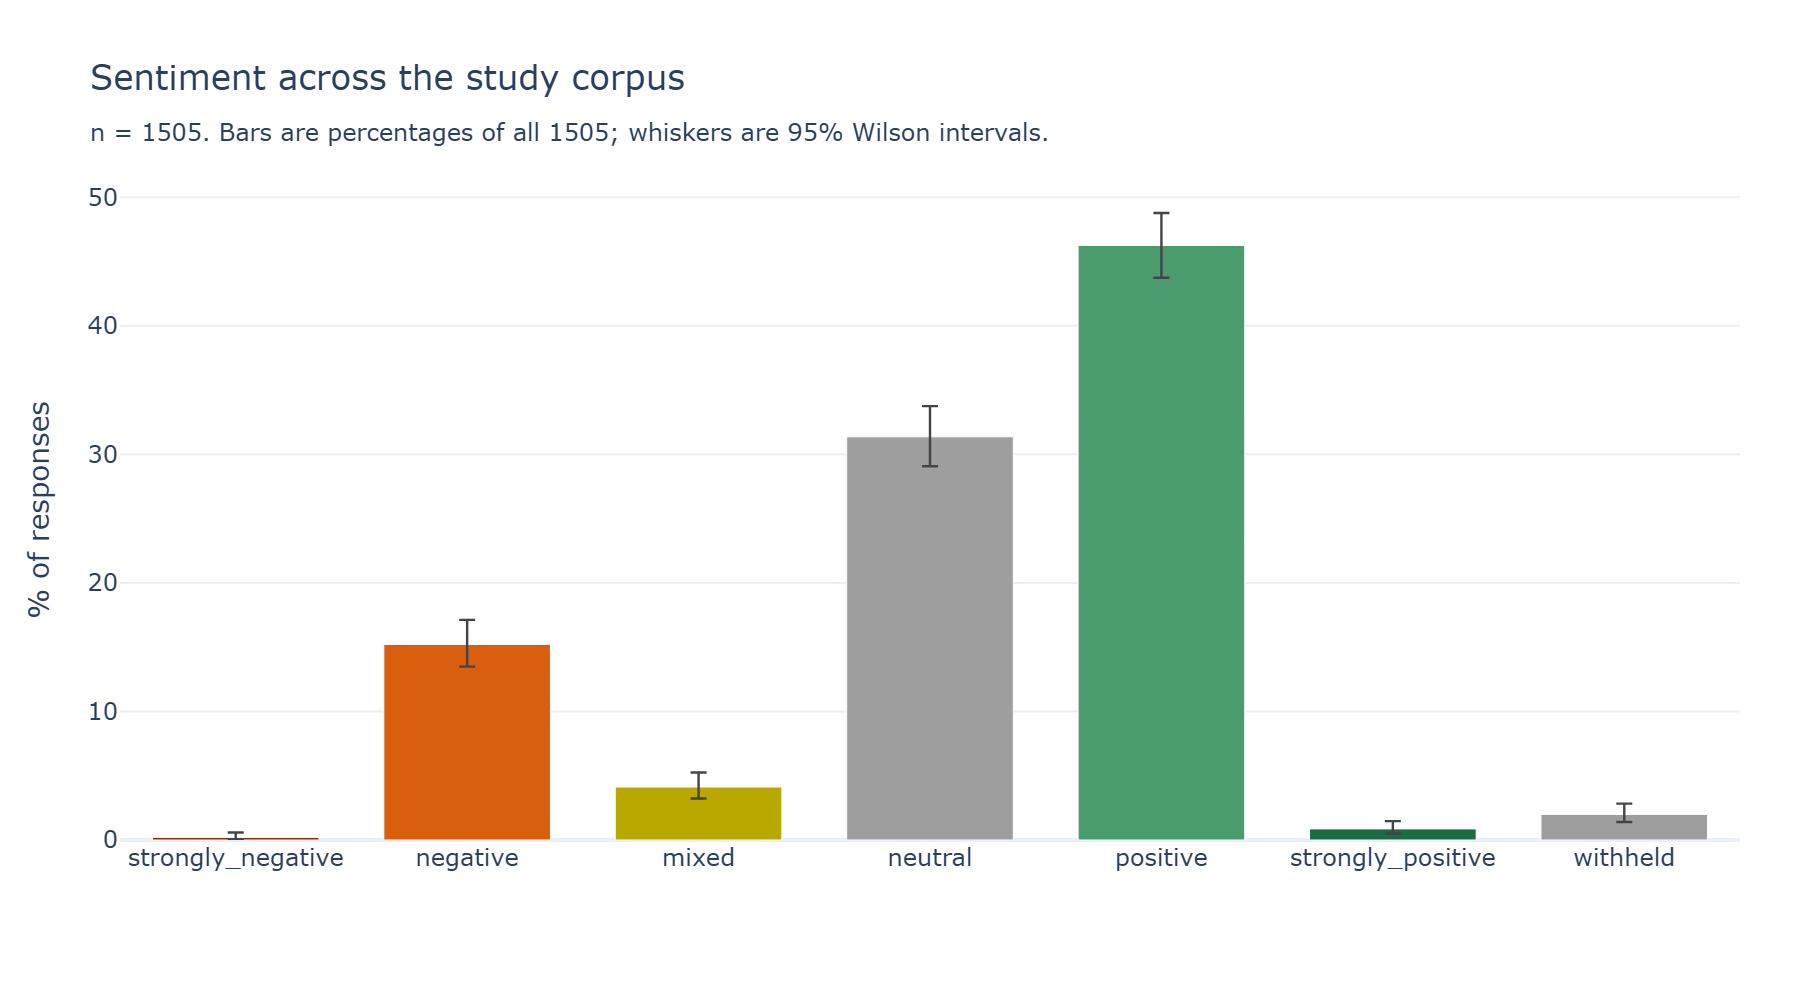

In [4]:
from broadlisten.explore import sentiment_bars

# Distribution among responses that received a verdict, plus the ones refused.
SCORED = {"positive": 696, "neutral": 472, "negative": 229, "mixed": 62,
          "strongly_positive": 13, "strongly_negative": 3}
WITHHELD = 30
print(f"scored {sum(SCORED.values())} + withheld {WITHHELD} "
      f"= {sum(SCORED.values()) + WITHHELD} responses")

png(sentiment_bars(SCORED, withheld=WITHHELD,
                   title="Sentiment across the study corpus"), h=500)

**Thirty responses were refused**, and they are on the chart. They are
not neutral and they are not absent: they are responses whose verdict failed its
citation check. Left off, every other percentage on this chart would be higher
and the corpus would look smaller than it is.

**Next:** [7. Statistics](07_statistics.ipynb).